In [299]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io.wavfile as wavfile
from pathlib import Path
from IPython.display import Audio, display
import scipy.io.wavfile as wavfile

### Funciones auxiliares

In [300]:
def play_audio(signal, sample_rate):
    display(Audio(signal, rate=sample_rate, normalize=False))

In [301]:
def der_tanh(y):
    return (1+y)*(1-y)

In [302]:
def reconstruct(model, signal, y_start=None):
    """
    Pasa `signal` (señal regular) por el modelo muestra a muestra
    y devuelve la señal 8-bit predicha.
    """
    if y_start is None:
        y_start = np.zeros(model.W.shape[0])

    y = y_start.copy()
    out = []

    for x in signal:
        y = model.forward(np.array([[x]]), y)[-1]
        out.append(y[0])

    return np.array(out, dtype=np.float32)

In [303]:
def reconstruct_nn(model, signal, window=30, y_start=None):
    """
    Reconstrucción para el modelo n→n: procesa la señal ventana a ventana.
    Cada ventana de `window` muestras es un timestep de entrada y salida.
    """
    if y_start is None:
        y_start = np.zeros(model.W.shape[0])

    y = y_start.copy()
    out = []

    n_windows = len(signal) // window
    for i in range(n_windows):
        x = signal[i*window : (i+1)*window].reshape(1, -1)  # (1, window)
        y = model.forward(x, y)[-1]                          # (n_outputs,)
        out.append(y)

    return np.concatenate(out).astype(np.float32)

In [ ]:
def save_wav(signal, fm, filename):
    path = f"../data/output/{filename}.wav"
    pcm = np.clip(signal, -1.0, 1.0)
    pcm = (pcm * 32767).astype(np.int16)
    wavfile.write(path, fm, pcm)
    print(f"Guardado: {path}")

In [305]:
class BPTT:
    def __init__(self, n_inputs, n_outputs, f_act=np.tanh, der_f_act=der_tanh):
        self.f_act = f_act
        self.der_f_act = der_f_act
        self.W_1     = np.random.rand(n_outputs, n_inputs)  * 0.01
        self.W       = np.random.rand(n_outputs, n_outputs) * 0.01
        self.b       = np.zeros(n_outputs)
        self.history = []

    def one_hot(self, V, index):
        x = np.zeros(V)
        x[index] = 1
        return x

    def forward(self, X, y_start):
        y, Y = y_start, []
        for t in range(X.shape[0]):
            y = self.f_act(self.W_1 @ X[t] + self.W @ y + self.b)
            Y.append(y)
        return np.array(Y)

    def backward(self, X, Y_hat, Y_D, y_start):
        d_W1  = np.zeros_like(self.W_1)
        d_W   = np.zeros_like(self.W)
        d_b   = np.zeros_like(self.b)
        delta = np.zeros(self.W.shape[0])

        for t in range(X.shape[0] - 1, -1, -1):
            delta = (Y_hat[t] - Y_D[t] + self.W.T @ delta) * self.der_f_act(Y_hat[t])
            d_W1 += np.outer(delta, X[t])
            d_W  += np.outer(delta, Y_hat[t - 1] if t > 0 else y_start)
            d_b  += delta

        return d_W1, d_W, d_b

    def fit(self, phrases, Y_D_phrases, lr=0.01, epochs=1000):
        X_all   = np.array(phrases)
        Y_D_all = np.array(Y_D_phrases)
        N, T, _ = X_all.shape
        n_out   = self.W.shape[0]
        self.history = []

        for epoch in range(epochs):
            y     = np.zeros((N, n_out))
            Y_hat = np.empty((N, T, n_out))
            for t in range(T):
                y = self.f_act(X_all[:, t] @ self.W_1.T + y @ self.W.T + self.b)
                Y_hat[:, t] = y

            d_W1  = np.zeros_like(self.W_1)
            d_W   = np.zeros_like(self.W)
            d_b   = np.zeros_like(self.b)
            delta = np.zeros((N, n_out))

            for t in range(T - 1, -1, -1):
                y_prev = Y_hat[:, t - 1] if t > 0 else np.zeros((N, n_out))
                delta  = (Y_hat[:, t] - Y_D_all[:, t] + delta @ self.W) * self.der_f_act(Y_hat[:, t])
                d_W1  += delta.T @ X_all[:, t]
                d_W   += delta.T @ y_prev
                d_b   += delta.sum(axis=0)

            self.W_1 -= lr * d_W1 / N
            self.W   -= lr * d_W  / N
            self.b   -= lr * d_b  / N

            mse = np.mean((Y_hat - Y_D_all) ** 2)
            self.history.append(mse)
            print(f"Época {epoch + 1}/{epochs} | MSE: {mse:.6f}", end="\r")
        print()

    def generate_phrase(self, x0, L):
        x = x0
        y = np.zeros_like(x0)
        Y = [x0]
        for _ in range(1, L):
            y = self.forward(x.reshape(1, -1), y)
            y = y[-1]
            y_oh = self.one_hot(V=len(x0), index=np.argmax(y))
            Y.append(y_oh)
            x = y_oh
        return Y

    def compute_gradient_norms(self, Y_hat, Y_D, t_fixed):
        delta = Y_hat[t_fixed] - Y_D[t_fixed]
        norms = []
        for k in range(t_fixed, -1, -1):
            delta = delta * self.der_f_act(Y_hat[k])
            norms.append(np.linalg.norm(delta))
            delta = self.W.T @ delta
        return norms

In [306]:
import warnings

DATA_DIR = Path("../data/signals")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sr_reg,  regular = wavfile.read(DATA_DIR / "regular/sec-2.wav")
    sr_8bit, bit8    = wavfile.read(DATA_DIR / "8bit/sec-2.wav")

if regular.ndim == 2: regular = regular[:, 0]
if bit8.ndim    == 2: bit8    = bit8[:, 0]

regular = regular.astype(np.float32) / np.iinfo(regular.dtype).max
bit8    = bit8.astype(np.float32)    / np.iinfo(bit8.dtype).max

print(f"Regular : {regular.shape}, {sr_reg} Hz")
print(f"8-bit   : {bit8.shape}, {sr_8bit} Hz")

Regular : (92731,), 22050 Hz
8-bit   : (92731,), 22050 Hz


In [307]:
WINDOW = 5

# cantidad de ventanas completas disponibles (restamos 1 por el shift)
n_windows = (min(len(regular), len(bit8)) - 1) // WINDOW

# X: ventanas de la señal regular → [i*30 : i*30 + 30]
# y: mismas ventanas en la señal 8bit pero desplazadas 1 muestra → [i*30+1 : i*30+31]
X = np.stack([regular[i*WINDOW     : i*WINDOW + WINDOW    ] for i in range(n_windows)])
y = np.stack([bit8   [i*WINDOW + 1 : i*WINDOW + WINDOW + 1] for i in range(n_windows)])

print(f"X (regular): {X.shape}")
print(f"y (8-bit)  : {y.shape}")

X (regular): (18546, 5)
y (8-bit)  : (18546, 5)


### Prueba 1: una sola neurona

In [308]:
fm = 22050

In [309]:
phrases     = [X[i].reshape(-1, 1) for i in range(len(X))]
Y_D_phrases = [y[i].reshape(-1, 1) for i in range(len(y))]

idx = np.random.permutation(len(phrases))
phrases     = [phrases[i]     for i in idx]
Y_D_phrases = [Y_D_phrases[i] for i in idx]

model = BPTT(n_inputs=1, n_outputs=1)
model.fit(phrases, Y_D_phrases, lr=0.01, epochs=100)

Época 100/100 | MSE: 0.221993


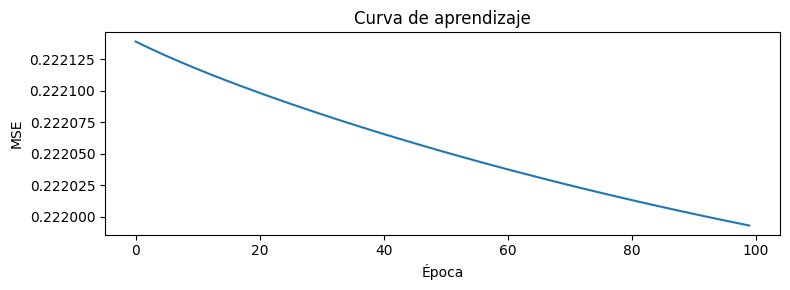

In [310]:
plt.figure(figsize=(8, 3))
plt.plot(model.history)
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Curva de aprendizaje")
plt.tight_layout()
plt.show()

In [311]:
reconstruction = reconstruct(model, regular)

In [312]:
reconstruction

array([ 3.1391925e-03,  3.6882474e-03,  3.6527894e-03, ...,
        4.5596663e-04, -5.8396719e-05,  1.1772768e-03],
      shape=(92731,), dtype=float32)

In [313]:
play_audio(reconstruction,fm)

### Prueba 2: n entradas y n salidas

In [314]:
# cada ventana de WINDOW muestras es un único timestep: shape (1, WINDOW)
phrases_nn     = [X[i].reshape(1, -1) for i in range(len(X))]
Y_D_phrases_nn = [y[i].reshape(1, -1) for i in range(len(y))]

idx = np.random.permutation(len(phrases_nn))
phrases_nn     = [phrases_nn[i]     for i in idx]
Y_D_phrases_nn = [Y_D_phrases_nn[i] for i in idx]

model_nn = BPTT(n_inputs=WINDOW, n_outputs=WINDOW)
model_nn.fit(phrases_nn, Y_D_phrases_nn, lr=0.01, epochs=3000)

Época 3000/3000 | MSE: 0.221811


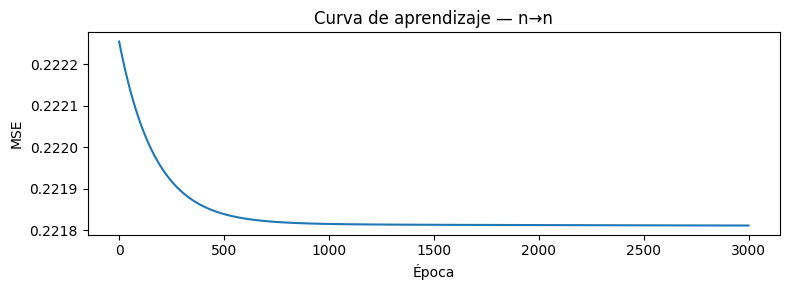

In [315]:
plt.figure(figsize=(8, 3))
plt.plot(model_nn.history)
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Curva de aprendizaje — n→n")
plt.tight_layout()
plt.show()

In [316]:
reconstruction_nn = reconstruct_nn(model_nn, regular, window=WINDOW)
play_audio(reconstruction_nn, fm)

In [ ]:
save_wav(signal=reconstruction_nn, fm=fm, filename="sec-2")

TypeError: save_wav() missing 2 required positional arguments: 'fm' and 'filename'